<a href="https://colab.research.google.com/github/ayuannisa17/PCdVK_ganjil_2026/blob/main/week7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## D. PRAKTIKUM FILTER

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv
import math

from google.colab.patches import cv2_imshow
from PIL import Image as im

## 2. Buatlah fungsi konvolusi.

In [5]:
def convolution2d(image, kernel, stride, padding):
    # Menambahkan padding pada citra
    image_padded = np.pad(image, ((padding, padding), (padding, padding)), mode='constant')

    # Ukuran citra dan kernel
    image_height, image_width = image_padded.shape
    kernel_height, kernel_width = kernel.shape

    # Ukuran output
    output_height = (image_height - kernel_height) // stride + 1
    output_width = (image_width - kernel_width) // stride + 1

    # Matriks output
    output = np.zeros((output_height, output_width))

    # Proses konvolusi
    for y in range(0, output_height):
        for x in range(0, output_width):
            region = image_padded[
                y * stride:y * stride + kernel_height,
                x * stride:x * stride + kernel_width
            ]
            output[y, x] = np.sum(region * kernel)

    # Mengembalikan hasil konvolusi
    return output

# Load citra yang akan diproses dan ubah menjadi citra keabuan


In [7]:
img = cv.imread('/content/drive/MyDrive/PCdVK/OIP.jpg')
img_gray = cv.cvtColor(img,cv.COLOR_BGR2GRAY)

# Menentukan kernel sharpening

In [8]:
kernel_sharpen = np.array([[0,-1,0],
                           [-1,5,-1],
                           [0,-1,0]])

# Memanggil fungsi konvolusi

In [9]:
convolution2d(img_gray,kernel_sharpen,1, 2)

array([[   0., -252., -244., ..., -237., -241.,    0.],
       [-252.,  768.,  493., ...,  474.,  728., -241.],
       [-248.,  504.,  243., ...,  240.,  484., -240.],
       ...,
       [ -95.,  185.,   86., ...,  155.,  310., -155.],
       [ -97.,  292.,  190., ...,  311.,  475., -157.],
       [   0.,  -97.,  -98., ..., -155., -157.,    0.]])

## 3. Buat Image Filter untuk Average filter, low pass filter, high pass filter, dan beberapa filter

In [10]:
# Sharpen
kernel_sharpen = np.array([[0,-1,0],
                           [-1,5,-1],
                           [0,-1,0]])

In [11]:
# embos
kernel_emboss = np.array([[-2,-1,0],
                          [-1,1,1],
                          [0,1,2]])

In [12]:
# Left Sobel Edge Detection
kernel_sobel = np.array([[1,0,-1],
                         [2,0,-2],
                         [1,0,-1]])

In [13]:
# Canny Edge Detection
kernel_canny = np.array([[-1,-1,-1],
                         [-1, 8,-1],
                         [-1,-1,-1]])

In [14]:
# 21x21 Gaussian Blur
kernel_size = 21
sigma = math.sqrt(kernel_size)
gaussian_kernel = cv.getGaussianKernel(kernel_size, sigma)
gauss_kernel = gaussian_kernel @ gaussian_kernel.transpose()

## E. FILTER LIBRARY DAN FILTER MODERN

#percobaan 1

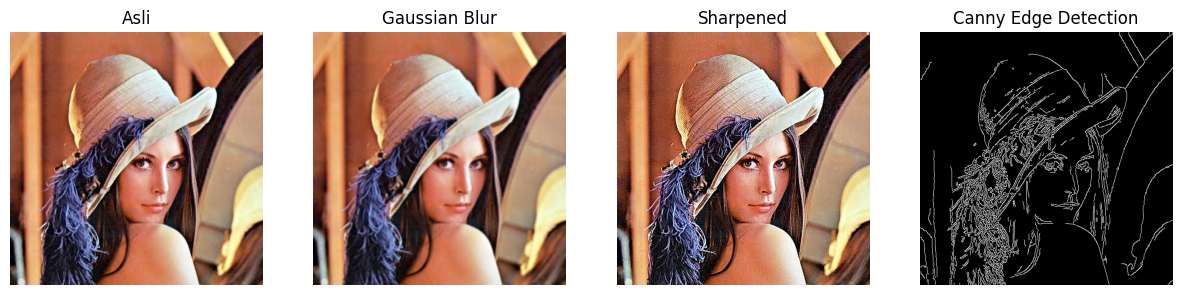

In [15]:
# Fungsi tampil berdampingan
def show_side_by_side(images, titles, figsize=(15,5)):
    plt.figure(figsize=figsize)
    for i, (img, title) in enumerate(zip(images, titles)):
        if len(img.shape) == 2: # grayscale
            plt.subplot(1, len(images), i+1)
            plt.imshow(img, cmap="gray")
        else: # color
            plt.subplot(1, len(images), i+1)
            plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
        plt.title(title)
        plt.axis("off")
    plt.show()

img = cv.imread("/content/drive/MyDrive/PCdVK/lenna.jpg")
img_gray = cv.cvtColor(img,cv.COLOR_BGR2GRAY)

blur = cv.GaussianBlur(img, (7,7), 1)
edges = cv.Canny(cv.cvtColor(img, cv.COLOR_BGR2GRAY), 100, 200)
sharpen_kernel = np.array([[0,-1,0],[-1,5,-1],[0,-1,0]])
sharpened = cv.filter2D(img, -1, sharpen_kernel)
show_side_by_side([img, blur, sharpened, edges],
                  ["Asli", "Gaussian Blur", "Sharpened", "Canny Edge Detection"])

#percobaan 2

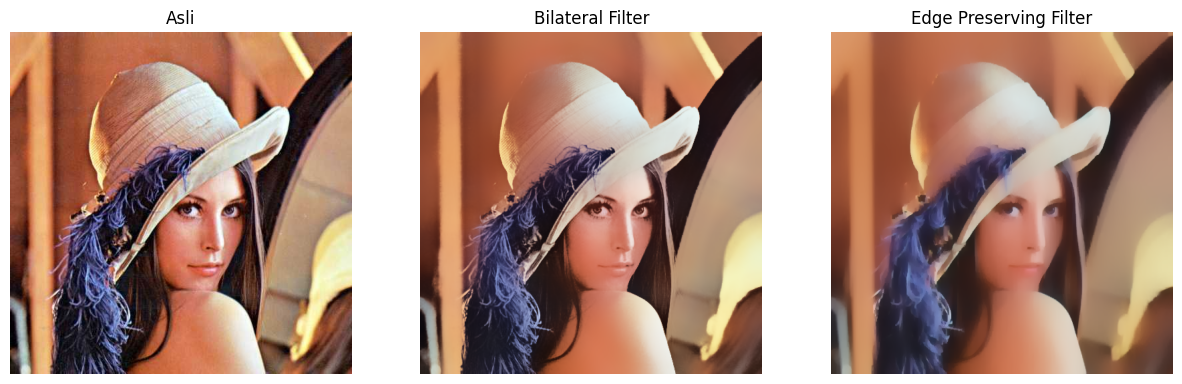

In [16]:
# Filter Modern dari OpenCV

# Bilateral Filter (edge-preserving)
bilateral = cv.bilateralFilter(img, 50, 100, 100)

# Edge Preserving Filter (alternatif Guided Filter)
edge_preserve = cv.edgePreservingFilter(img, flags=1, sigma_s=100, sigma_r=0.9)

show_side_by_side([img, bilateral, edge_preserve],
                  ["Asli", "Bilateral Filter", "Edge Preserving Filter"])

#percobaan 3

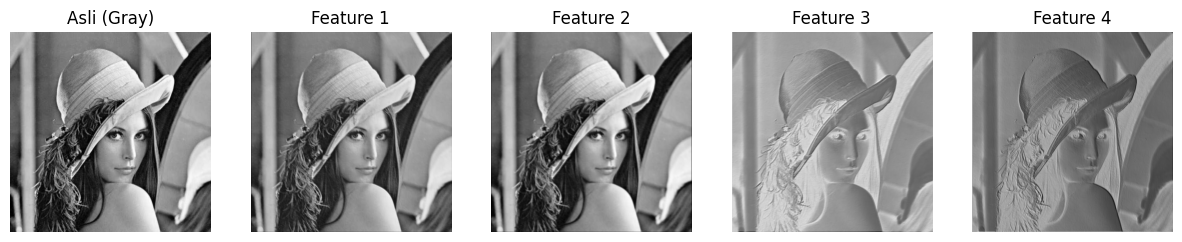

In [17]:
#Filter Feature Map yang digunakan pada CNN, Lakukan running code bagian ini beberapa kali dan perhatikan hasilnya
import torch
import torch.nn as nn

class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 4, kernel_size=3, stride=1, padding=1)

    def forward(self, x):
        return self.conv1(x)

model = SimpleCNN()

# Ubah gambar ke tensor
img_tensor = torch.tensor(img_gray, dtype=torch.float32).unsqueeze(0).unsqueeze(0) / 255.0

# Hasil CNN
with torch.no_grad():
    features = model(img_tensor)

# Visualisasi feature maps
feature_maps = [features[0,i].numpy() for i in range(features.shape[1])]
show_side_by_side([img_gray] + feature_maps,
                  ["Asli (Gray)"] + [f"Feature {i+1}" for i in range(len(feature_maps))])

#percoban 4

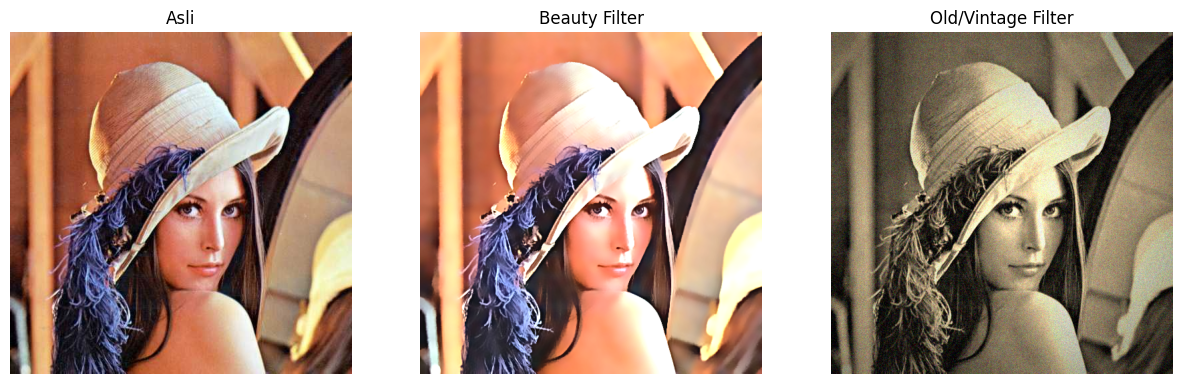

In [18]:
# 1. Beauty Filter

# Step 1: Smoothing kulit dengan bilateral filter
smooth = cv.bilateralFilter(img, d=15, sigmaColor=75, sigmaSpace=75)

# Step 2: Unsharp masking (pertajam mata/bibir)
gaussian = cv.GaussianBlur(smooth, (0,0), 3)
sharpened = cv.addWeighted(smooth, 1.5, gaussian, -0.5, 0)

# Step 3: Brightness & contrast
alpha = 1.2 # contrast
beta = 15 # brightness

beauty = cv.convertScaleAbs(sharpened, alpha=alpha, beta=beta)

# 2. Old/Vintage Filter

# Step 1: Sepia tone
sepia_kernel = np.array([[0.272, 0.534, 0.131],
                         [0.349, 0.686, 0.168],
                         [0.393, 0.769, 0.189]])

sepia = cv.transform(img, sepia_kernel)
sepia = np.clip(sepia, 0, 255).astype(np.uint8)

# Step 2: Vignette
rows, cols = img.shape[:2]
kernel_x = cv.getGaussianKernel(cols, cols*0.6)
kernel_y = cv.getGaussianKernel(rows, rows*0.6)
kernel = kernel_y * kernel_x.T
mask = kernel / kernel.max()
vignette = np.copy(sepia)
for i in range(3):
    vignette[:,:,i] = vignette[:,:,i] * mask

# Step 3: Noise/Grain
noise = np.random.normal(0, 15, vignette.shape).astype(np.int16)
old_img = np.clip(vignette.astype(np.int16) + noise, 0, 255).astype(np.uint8)

show_side_by_side([img, beauty, old_img],
                  ["Asli", "Beauty Filter", "Old/Vintage Filter"])

#percobaan 5

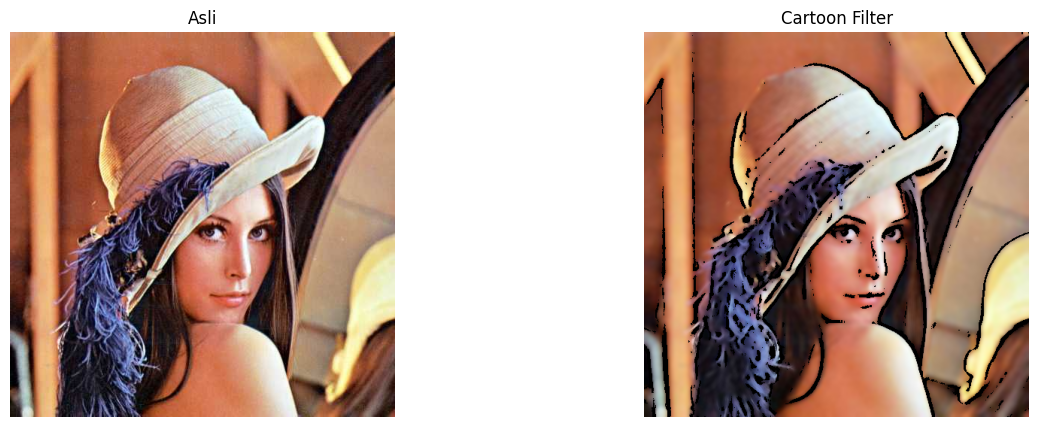

In [19]:
#Filter Anime / Cartoon

# Step 1: Edge detection (pakai median blur dulu agar gambar menjadi lebih halus)
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

gray_blur = cv.medianBlur(gray, 7)

edges = cv.adaptiveThreshold(gray_blur, 255,
                             cv.ADAPTIVE_THRESH_MEAN_C,
                             cv.THRESH_BINARY, 9, 9)

# Step 2: Bilateral filter untuk smoothing warna
color = cv.bilateralFilter(img, d=9, sigmaColor=200, sigmaSpace=200)

# Step 3: Gabungkan (cartoonize)
cartoon = cv.bitwise_and(color, color, mask=edges)

# Tampilkan
show_side_by_side([img, cartoon], ["Asli", "Cartoon Filter"])

#percobaan 6

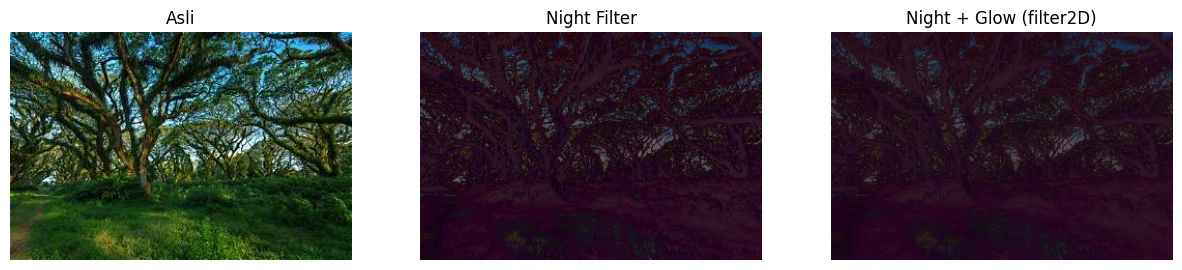

In [21]:
#Night Filter
img = cv.imread("/content/drive/MyDrive/PCdVK/djawatan.jpg")
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# Step 1: Gelapkan (contrast turun, brightness negatif)
night = cv.convertScaleAbs(img, alpha=0.6, beta=-40)

# Step 2: Tambah bias biru
blue_tint = np.full_like(night, (50, 0, 100)) # BGR
night = cv.addWeighted(night, 0.8, blue_tint, 0.2, 0)

# Step 3: Efek glow di area terang dengan filter2D (blur kernel)
kernel = np.ones((15,15), np.float32) / 225
glow = cv.filter2D(night, -1, kernel)

# Kombinasikan asli + glow
night_glow = cv.addWeighted(night, 0.7, glow, 0.3, 0)

show_side_by_side([img, night, night_glow],
                  ["Asli", "Night Filter", "Night + Glow (filter2D)"])

#percobaan 7

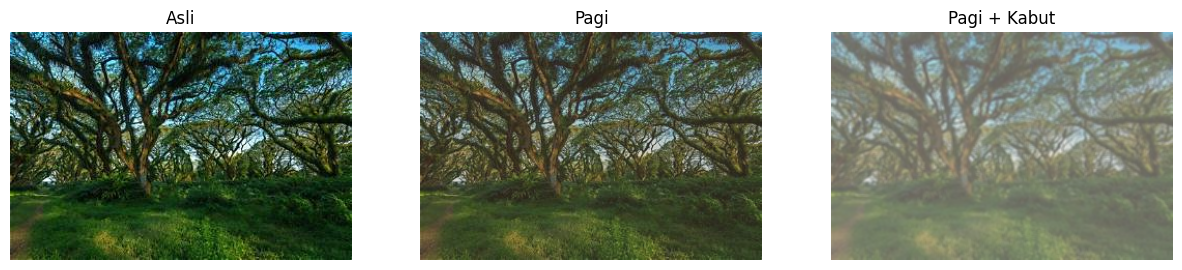

In [26]:
# Step 1: Kurangi kontras dan cerahkan
alpha = 0.9  # contrast
beta = 20    # brightness
soft = cv.convertScaleAbs(img, alpha=alpha, beta=beta)

# ============================
# Step 2: Tambahkan warm tone (kemerahan / oranye)
# ============================
warm_tint = np.full_like(soft, (40, 70, 120))  # BGR
pagi = cv.addWeighted(soft, 0.8, warm_tint, 0.2, 0)

# ============================
# Step 3: Tambahkan haze (kabut tipis) dengan filter2D
# ============================
kernel = cv.getGaussianKernel(3, 3)
kernel = kernel @ kernel.T  # jadikan 2D kernel
kabut = cv.filter2D(pagi, -1, kernel)

# tambah layer putih untuk kabut lebih nyata
white_layer = np.full_like(pagi, 255)
kabut = cv.addWeighted(kabut, 0.7, white_layer, 0.3, 0)

show_side_by_side([img, pagi, kabut],
                  ["Asli", "Pagi", "Pagi + Kabut"])

# TUGAS PRAKTIKUM

In [27]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv

img = cv.imread('/content/drive/MyDrive/PCdVK/lenna.jpg')

if img is None:
    raise FileNotFoundError("Gambar lena.jpg tidak ditemukan. Periksa lokasi file.")

img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

def show_side_by_side(images, titles, figsize=(15, 5)):
    plt.figure(figsize=figsize)

    for i, (image, title) in enumerate(zip(images, titles)):
        plt.subplot(1, len(images), i + 1)

        if len(image.shape) == 2:
            plt.imshow(image, cmap='gray')
        else:
            plt.imshow(cv.cvtColor(image, cv.COLOR_BGR2RGB))

        plt.title(title)
        plt.axis('off')

    plt.tight_layout()
    plt.show()

# 1. Tugas Analisis : Mean Filter vs. Median Filter

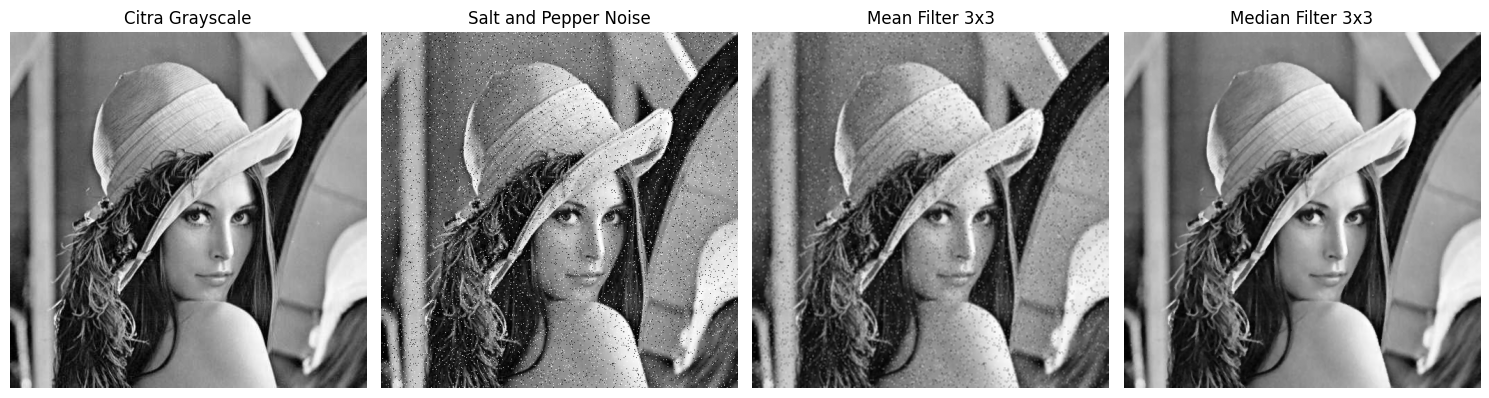

In [28]:
# A. Menambahkan Salt and Pepper Noise
noisy = img_gray.copy()

amount = 0.05
num_salt = int(amount * noisy.size / 2)
num_pepper = int(amount * noisy.size / 2)

coords = [
    np.random.randint(0, i, num_salt)
    for i in noisy.shape
]
noisy[coords[0], coords[1]] = 255

coords = [
    np.random.randint(0, i, num_pepper)
    for i in noisy.shape
]
noisy[coords[0], coords[1]] = 0

# B. Mean Filter 3 x 3
mean_filter = cv.blur(noisy, (3, 3))

# C. Median Filter 3 x 3
median_filter = cv.medianBlur(noisy, 3)

# D. Menampilkan hasil
show_side_by_side(
    [img_gray, noisy, mean_filter, median_filter],
    ['Citra Grayscale', 'Salt and Pepper Noise',
     'Mean Filter 3x3', 'Median Filter 3x3']
)

# 2. Tugas Evaluasi : Menentukan Kernel Sharpening Terbaik

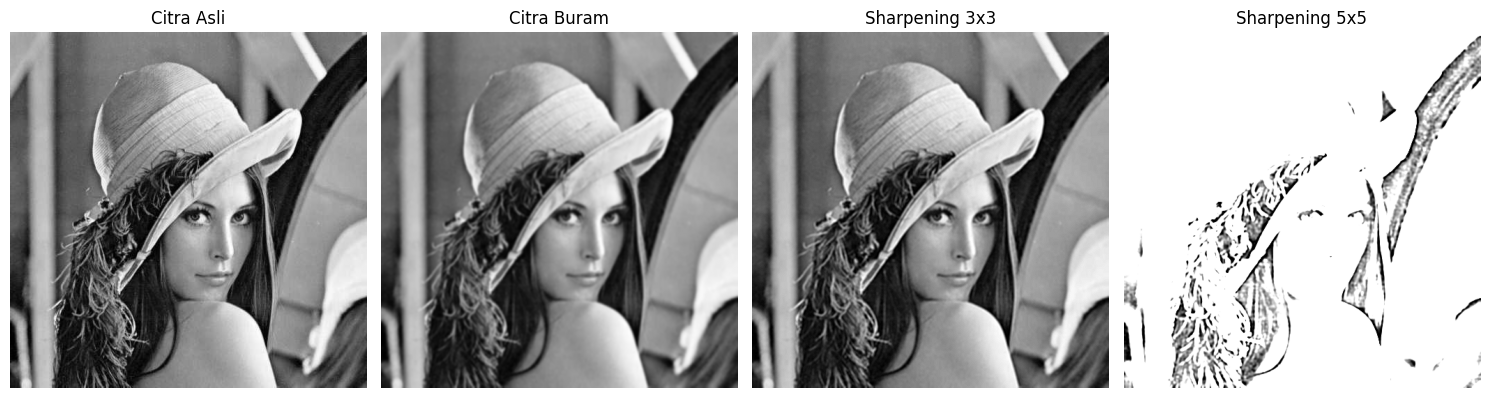

In [29]:
# A. Membuat citra sedikit buram
blurry = cv.GaussianBlur(img_gray, (5, 5), 1.5)

# B. Kernel Sharpening 3 x 3
kernel_3x3 = np.array([
    [ 0, -1,  0],
    [-1,  5, -1],
    [ 0, -1,  0]
], dtype=np.float32)

# C. Kernel Sharpening 5 x 5
kernel_5x5 = np.array([
    [-1, -1, -1, -1, -1],
    [-1,  2,  2,  2, -1],
    [-1,  2,  8,  2, -1],
    [-1,  2,  2,  2, -1],
    [-1, -1, -1, -1, -1]
], dtype=np.float32)

# D. Menerapkan filter sharpening
sharpen_3x3 = cv.filter2D(blurry, -1, kernel_3x3)
sharpen_5x5 = cv.filter2D(blurry, -1, kernel_5x5)

# E. Menampilkan hasil
show_side_by_side(
    [img_gray, blurry, sharpen_3x3, sharpen_5x5],
    ['Citra Asli', 'Citra Buram',
     'Sharpening 3x3', 'Sharpening 5x5']
)

# 3. Tugas Kreasi: Filter Kartun Sederhana

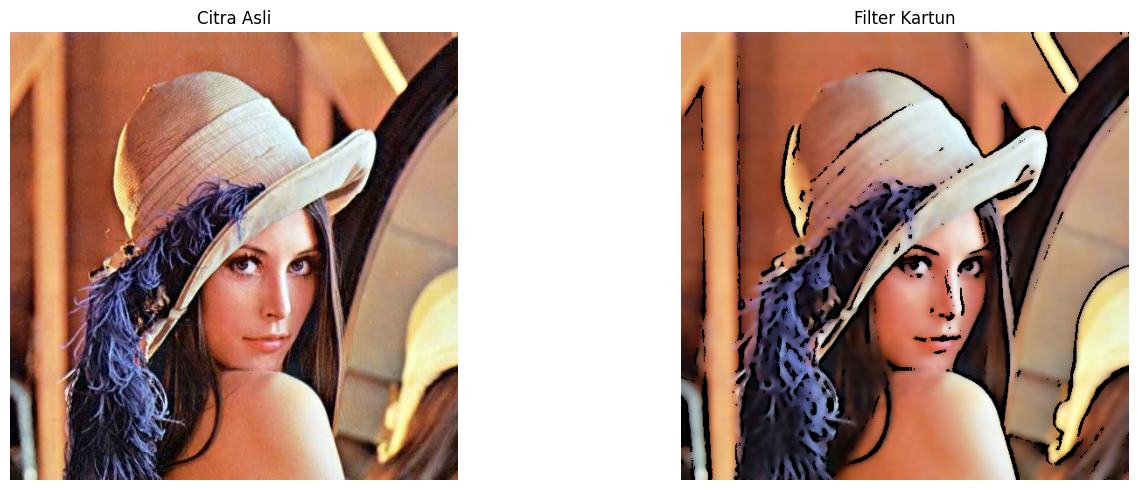

In [30]:
def kartun(image):
    # 1. Penghalusan warna menggunakan Bilateral Filter
    color = cv.bilateralFilter(
        image, 9, 200, 200
    )

    # 2. Mengubah citra menjadi grayscale
    gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)

    # 3. Menghaluskan grayscale
    gray_blur = cv.medianBlur(gray, 7)

    # 4. Deteksi garis tepi menggunakan Adaptive Thresholding
    edges = cv.adaptiveThreshold(
        gray_blur,
        255,
        cv.ADAPTIVE_THRESH_MEAN_C,
        cv.THRESH_BINARY,
        9,
        9
    )

    # 5. Menggabungkan warna dan garis tepi
    cartoon_image = cv.bitwise_and(
        color, color, mask=edges
    )

    return cartoon_image


# Memanggil fungsi kartun
hasil_kartun = kartun(img)

# Menampilkan citra asli dan hasil kartun
show_side_by_side(
    [img, hasil_kartun],
    ['Citra Asli', 'Filter Kartun']
)